[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jseborga/recursos-ia/blob/main/notebooks/05_matrices_tensores.ipynb)

# Ecuaciones, matrices y tensores con SymPy y NumPy

Seis ejemplos para mostrar qué hacen bien las librerías de matemáticas de Python: resolver sistemas en símbolos, encontrar autovalores, manejar tensores con índices y demostrar identidades. Como en los demás cuadernos, cada resultado se compara con algo independiente y el cuaderno se detiene con `✘` si no coincide.

| # | Ejemplo | Librería | Materias relacionadas | Control |
|---|---|---|---|---|
| 1 | Circuito de dos mallas (leyes de Kirchhoff) | SymPy | Física Básica, circuitos | Sustituir la solución da residuo 0 |
| 2 | Matriz de Hilbert: un sistema que «parece» resuelto | NumPy | FIS-243 Cálculo Numérico | Residuo pequeño, error grande |
| 3 | Modos normales de masas acopladas | SymPy + NumPy | FIS-240 Mecánica Clásica | Fórmula cerrada de las frecuencias |
| 4 | Tensor de inercia de una caja rotada | NumPy `einsum` | FIS-240 Mecánica Clásica | Momentos principales analíticos |
| 5 | Símbolo de Levi-Civita y producto vectorial | NumPy `einsum` | FIS-132 / FIS-242 Métodos Matemáticos | Identidad ε·ε = δδ − δδ exacta |
| 6 | Transformación de Lorentz y tensor métrico | SymPy + NumPy | Física Moderna (relatividad especial)* | Λᵀ η Λ = η en símbolos |

\*Verifique en el sílabo vigente en qué materia se ve relatividad especial; aquí no se confirmó.

*Entorno de ejecución → Ejecutar todo.* SymPy, NumPy, SciPy y Matplotlib vienen instalados en Colab.

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.linalg import hilbert, eigh
from scipy.spatial.transform import Rotation

sp.init_printing()
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

def verificar(condicion, mensaje):
    if not condicion:
        raise AssertionError("✘ " + mensaje)
    print("✔", mensaje)

## 1 · Circuito de dos mallas en símbolos (SymPy)

Dos fuentes $E_1$, $E_2$ y tres resistencias; $R_3$ es común a las dos mallas. Con corrientes de malla $I_1$, $I_2$ (sentido horario):

$$(R_1+R_3)\,I_1 - R_3\,I_2 = E_1,\qquad -R_3\,I_1 + (R_2+R_3)\,I_2 = -E_2$$

SymPy resuelve el sistema **sin números**: la respuesta es una fórmula que el estudiante puede analizar (¿qué pasa si $R_3\to 0$? ¿y si $R_3\to\infty$?).

In [2]:
R1, R2, R3, E1, E2 = sp.symbols("R1 R2 R3 E1 E2", positive=True)
I1, I2 = sp.symbols("I1 I2")
ecuaciones = [sp.Eq((R1 + R3)*I1 - R3*I2, E1),
              sp.Eq(-R3*I1 + (R2 + R3)*I2, -E2)]
sol = sp.solve(ecuaciones, [I1, I2], dict=True)[0]
display(sp.Eq(I1, sp.factor(sol[I1])), sp.Eq(I2, sp.factor(sol[I2])))

# Control 1: la solución simbólica satisface las ecuaciones idénticamente
residuos = [sp.simplify(e.lhs.subs(sol) - e.rhs) for e in ecuaciones]
verificar(all(r == 0 for r in residuos), "al sustituir la solución simbólica, ambas ecuaciones dan residuo 0")

# Control 2: con números, coincide con un solver numérico independiente
valores = {R1: 10, R2: 20, R3: 30, E1: 12, E2: 6}
A = np.array([[40, -30], [-30, 50]], float); b = np.array([12, -6], float)
x = np.linalg.solve(A, b)
simb = np.array([float(sol[I1].subs(valores)), float(sol[I2].subs(valores))])
print(f"I1 = {simb[0]*1000:.3f} mA, I2 = {simb[1]*1000:.3f} mA")
verificar(np.allclose(simb, x, rtol=1e-14), "la fórmula de SymPy y numpy.linalg.solve dan las mismas corrientes")

# Caso límite: si R3 → 0 las mallas se desacoplan e I1 → E1/R1
verificar(sp.simplify(sp.limit(sol[I1], R3, 0) - E1/R1) == 0, "límite R3 → 0: I1 = E1/R1, como se espera de mallas independientes")

✔ al sustituir la solución simbólica, ambas ecuaciones dan residuo 0
I1 = 381.818 mA, I2 = 109.091 mA
✔ la fórmula de SymPy y numpy.linalg.solve dan las mismas corrientes
✔ límite R3 → 0: I1 = E1/R1, como se espera de mallas independientes


## 2 · Un sistema que parece resuelto y no lo está

La matriz de Hilbert $H_{ij} = 1/(i+j-1)$ es simétrica e invertible, pero está muy mal condicionada. Fabricamos un sistema cuya solución exacta conocemos ($\mathbf x = (1,1,\dots,1)$) y le pedimos a NumPy que lo resuelva.

El **residuo** $\|H\hat{\mathbf x}-\mathbf b\|$ sale minúsculo para todo $n$: si solo miramos eso, todo «funcionó». El **error** real $\|\hat{\mathbf x}-\mathbf x\|$ crece como el número de condición. Es el equivalente algebraico de las simulaciones que se ven bien.

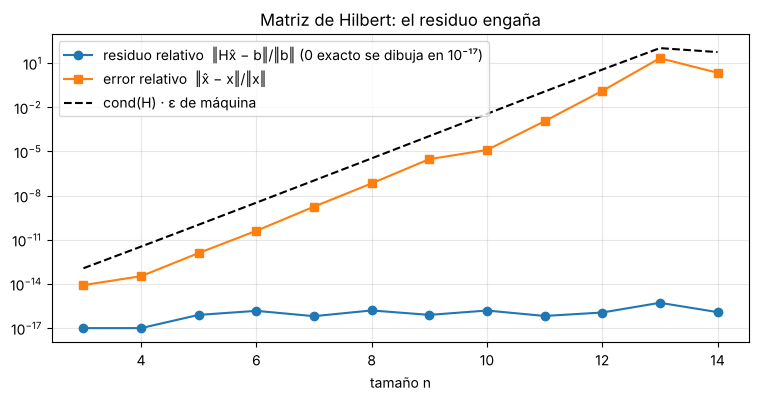

n = 12: cond(H) = 1.6e+16, residuo = 1.1e-16, error = 1.3e-01
✔ el residuo es siempre minúsculo (máx. 5.2e-16)
✔ pero con n = 12 la solución está mal en el 12.89 %
✔ el error queda por debajo de la cota cond(H)·ε (con margen 50): la teoría lo predice


In [3]:
ns = np.arange(3, 15)
residuo, error, cond = [], [], []
for n in ns:
    H = hilbert(n); x_ex = np.ones(n); b = H @ x_ex
    x = np.linalg.solve(H, b)
    residuo.append(np.linalg.norm(H @ x - b) / np.linalg.norm(b))
    error.append(np.linalg.norm(x - x_ex) / np.linalg.norm(x_ex))
    cond.append(np.linalg.cond(H))
residuo, error, cond = map(np.array, (residuo, error, cond))

plt.semilogy(ns, np.maximum(residuo, 1e-17), "o-", label="residuo relativo  ‖Hx̂ − b‖/‖b‖ (0 exacto se dibuja en 10⁻¹⁷)")
plt.semilogy(ns, error, "s-", label="error relativo  ‖x̂ − x‖/‖x‖")
plt.semilogy(ns, cond * np.finfo(float).eps, "k--", label="cond(H) · ε de máquina")
plt.xlabel("tamaño n"); plt.legend(); plt.title("Matriz de Hilbert: el residuo engaña"); plt.show()

i = list(ns).index(12)
print(f"n = 12: cond(H) = {cond[i]:.1e}, residuo = {residuo[i]:.1e}, error = {error[i]:.1e}")
verificar(residuo.max() < 1e-12, f"el residuo es siempre minúsculo (máx. {residuo.max():.1e})")
verificar(error[i] > 1e-3, f"pero con n = 12 la solución está mal en el {error[i]*100:.2f} %")
verificar(np.all(error[ns >= 6] < 50 * cond[ns >= 6] * np.finfo(float).eps),
          "el error queda por debajo de la cota cond(H)·ε (con margen 50): la teoría lo predice")

**Para el aula:** pidan a una IA que «resuelva el sistema» con una matriz de Hilbert de 12×12 y que diga si la solución es confiable. Si responde mirando solo el residuo, se equivoca. El número de condición es la pregunta correcta.

## 3 · Modos normales de masas acopladas

Masas iguales $m$ unidas por resortes iguales $k$, con los extremos fijos a la pared. Las ecuaciones $m\ddot{\mathbf x} = -K\mathbf x$ llevan al problema de autovalores $K\mathbf v = m\,\omega^2\mathbf v$.

Primero dos masas, en símbolos; después $N$ masas, en números, contra la fórmula cerrada
$$\omega_n = 2\sqrt{k/m}\,\sin\!\left(\frac{n\pi}{2(N+1)}\right),\quad n=1,\dots,N.$$

ω² = k/m,  modo = [1, 1]
ω² = 3*k/m,  modo = [-1, 1]
✔ dos masas: ω² = k/m (en fase) y 3k/m (en contrafase), en símbolos


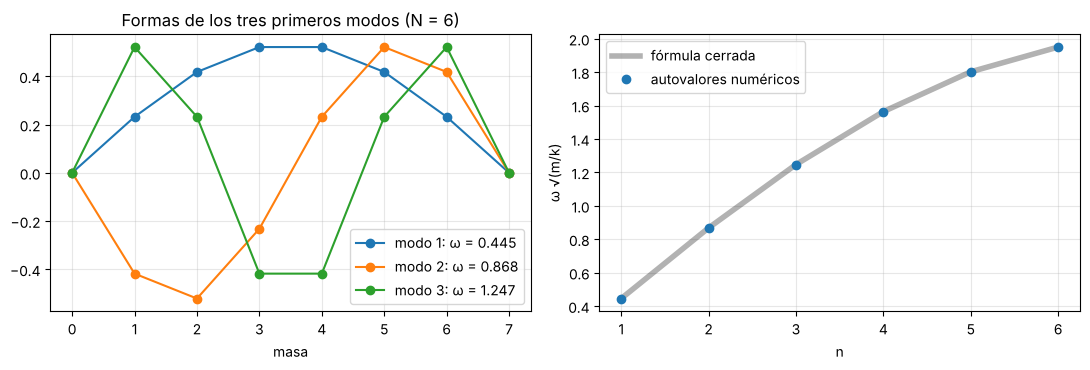

✔ las frecuencias numéricas coinciden con la fórmula cerrada (error < 10⁻¹²)
✔ los modos son ortonormales: VᵀV = I


In [4]:
k, m = sp.symbols("k m", positive=True)
K2 = sp.Matrix([[2*k, -k], [-k, 2*k]])
for valor, mult, vectores in (K2 / m).eigenvects():
    print(f"ω² = {valor},  modo = {list(vectores[0])}")
verificar(set((K2 / m).eigenvals()) == {k/m, 3*k/m},
          "dos masas: ω² = k/m (en fase) y 3k/m (en contrafase), en símbolos")

def matriz_K(N, k=1.0):
    return k * (2*np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1))

N = 6
w2, V = eigh(matriz_K(N))                       # m = k = 1
w_num = np.sqrt(w2)
w_ex = 2*np.sin(np.arange(1, N + 1)*np.pi/(2*(N + 1)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
xs = np.arange(0, N + 2)
for n in range(3):
    ax[0].plot(xs, np.r_[0, V[:, n], 0], "o-", label=f"modo {n+1}: ω = {w_num[n]:.3f}")
ax[0].set_xlabel("masa"); ax[0].set_title("Formas de los tres primeros modos (N = 6)"); ax[0].legend()
ax[1].plot(range(1, N + 1), w_ex, "k-", lw=4, alpha=.3, label="fórmula cerrada")
ax[1].plot(range(1, N + 1), w_num, "o", label="autovalores numéricos")
ax[1].set_xlabel("n"); ax[1].set_ylabel("ω √(m/k)"); ax[1].legend(); plt.tight_layout(); plt.show()
verificar(np.max(np.abs(w_num - w_ex)) < 1e-12, "las frecuencias numéricas coinciden con la fórmula cerrada (error < 10⁻¹²)")
verificar(np.allclose(V.T @ V, np.eye(N), atol=1e-12), "los modos son ortonormales: VᵀV = I")

## 4 · Tensor de inercia con `einsum`

Para un conjunto de masas puntuales, $I_{ij} = \sum_p m_p\,(r_p^2\,\delta_{ij} - r_{p,i}\,r_{p,j})$. Con `numpy.einsum` la fórmula se escribe casi igual que en la pizarra.

Tomamos una caja maciza de lados $a, b, c$ representada por una malla de puntos, la **rotamos** con una rotación arbitraria y calculamos el tensor. Sus autovalores deben ser los momentos principales de la caja, $\tfrac{M}{12}(b^2+c^2)$, etc., y sus autovectores, los ejes de la caja rotada.

In [5]:
a, b, c, M, n = 3.0, 2.0, 1.0, 1.0, 40
u = (np.arange(n) + 0.5)/n - 0.5                     # puntos medios de cada celda
X, Y, Z = np.meshgrid(a*u, b*u, c*u, indexing="ij")
r_caja = np.column_stack([X.ravel(), Y.ravel(), Z.ravel()])
masas = np.full(len(r_caja), M/len(r_caja))

R = Rotation.from_euler("zyx", [35, 20, -50], degrees=True).as_matrix()
r = r_caja @ R.T                                      # caja rotada

def tensor_inercia(m, r):
    return np.einsum("p,pk,pk->", m, r, r) * np.eye(3) - np.einsum("p,pi,pj->ij", m, r, r)

I = tensor_inercia(masas, r)
print("Tensor de inercia de la caja rotada (kg·m²):"); print(np.round(I, 4))
lam, ejes = eigh(I)
exactos = np.sort(M/12*np.array([b*b + c*c, a*a + c*c, a*a + b*b]))
print("momentos principales:", np.round(lam, 5), " analíticos:", np.round(exactos, 5))
verificar(np.max(np.abs(lam - exactos)/exactos) < 1e-3, "los autovalores son los momentos principales analíticos (malla de 40³ puntos)")
I_caja = tensor_inercia(masas, r_caja)
verificar(np.allclose(I, R @ I_caja @ R.T, atol=1e-12), "ley de transformación de un tensor de orden 2: I′ = R I Rᵀ")
alineacion = np.abs(np.sum(ejes * R, axis=0))   # menor momento ↔ eje del lado más largo a (columna 0 de R), y así sucesivamente
verificar(np.all(alineacion > 1 - 1e-9), "los ejes principales coinciden con las aristas de la caja rotada")

Tensor de inercia de la caja rotada (kg·m²):
[[0.6153 0.0121 0.2502]
 [0.0121 0.9524 0.1484]
 [0.2502 0.1484 0.7642]]
momentos principales: [0.41641 0.83281 1.08266]  analíticos: [0.41667 0.83333 1.08333]
✔ los autovalores son los momentos principales analíticos (malla de 40³ puntos)
✔ ley de transformación de un tensor de orden 2: I′ = R I Rᵀ
✔ los ejes principales coinciden con las aristas de la caja rotada


## 5 · Levi-Civita: demostrar una identidad con la computadora

El símbolo $\varepsilon_{ijk}$ vale $+1$ en permutaciones pares de $(1,2,3)$, $-1$ en impares y $0$ si se repite un índice. La identidad
$$\varepsilon_{ijk}\,\varepsilon_{imn} = \delta_{jm}\delta_{kn} - \delta_{jn}\delta_{km}$$
tiene $3^4 = 81$ componentes. Con enteros se comprueban **todas, sin redondeo**: es una demostración por enumeración, no una aproximación.

In [6]:
eps = np.zeros((3, 3, 3), dtype=int)
for (i, j, k_), s in {(0, 1, 2): 1, (1, 2, 0): 1, (2, 0, 1): 1, (0, 2, 1): -1, (2, 1, 0): -1, (1, 0, 2): -1}.items():
    eps[i, j, k_] = s
d = np.eye(3, dtype=int)
izq = np.einsum("ijk,imn->jkmn", eps, eps)
der = np.einsum("jm,kn->jkmn", d, d) - np.einsum("jn,km->jkmn", d, d)
verificar(np.array_equal(izq, der), "ε_ijk ε_imn = δ_jm δ_kn − δ_jn δ_km en sus 81 componentes, con aritmética entera exacta")

rng = np.random.default_rng(2026)
A_, B_, C_ = rng.normal(size=(3, 3))
verificar(np.allclose(np.einsum("ijk,j,k->i", eps, A_, B_), np.cross(A_, B_)), "(A × B)_i = ε_ijk A_j B_k coincide con numpy.cross")
verificar(np.isclose(np.einsum("ijk,i,j,k->", eps, A_, B_, C_), np.linalg.det(np.array([A_, B_, C_]))),
          "producto mixto A·(B × C) = det[A; B; C]")

✔ ε_ijk ε_imn = δ_jm δ_kn − δ_jn δ_km en sus 81 componentes, con aritmética entera exacta
✔ (A × B)_i = ε_ijk A_j B_k coincide con numpy.cross
✔ producto mixto A·(B × C) = det[A; B; C]


## 6 · Transformación de Lorentz y tensor métrico

Con $c = 1$, métrica $\eta = \mathrm{diag}(1,-1,-1,-1)$ y un impulso en $x$ con velocidad $\beta$:
$$\Lambda = \begin{pmatrix}\gamma & -\gamma\beta & 0 & 0\\ -\gamma\beta & \gamma & 0 & 0\\ 0&0&1&0\\0&0&0&1\end{pmatrix},\qquad \gamma = \frac{1}{\sqrt{1-\beta^2}}.$$

Que $\Lambda$ conserve el intervalo equivale a $\Lambda^{\mathsf T}\eta\,\Lambda = \eta$. SymPy lo comprueba **para todo β**, no para un valor.

✔ Λᵀ η Λ = η para cualquier β (demostración simbólica)


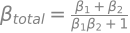

✔ dos impulsos seguidos = un impulso con la suma relativista de velocidades
0,8c + 0,8c = 0,9756c   (y no 1,6c)
✔ el intervalo s² = η_ij x^i x^j es el mismo en los tres sistemas


In [7]:
beta = sp.symbols("beta", real=True)
g = 1/sp.sqrt(1 - beta**2)
L = sp.Matrix([[g, -g*beta, 0, 0], [-g*beta, g, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
eta = sp.diag(1, -1, -1, -1)
verificar(sp.simplify(L.T*eta*L - eta) == sp.zeros(4), "Λᵀ η Λ = η para cualquier β (demostración simbólica)")

b1, b2 = sp.symbols("beta1 beta2", real=True)
Lb = lambda bb: L.subs(beta, bb)
compuesta = sp.simplify(Lb(b1)*Lb(b2))
b_suma = sp.simplify(-compuesta[0, 1]/compuesta[0, 0])
display(sp.Eq(sp.Symbol("beta_total"), sp.factor(b_suma)))
verificar(sp.simplify(b_suma - (b1 + b2)/(1 + b1*b2)) == 0, "dos impulsos seguidos = un impulso con la suma relativista de velocidades")

def boost(bb):
    gg = 1/np.sqrt(1 - bb**2)
    return np.array([[gg, -gg*bb, 0, 0], [-gg*bb, gg, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1]])
etaN = np.diag([1., -1, -1, -1])
evento = np.array([2.0, 0.7, -1.1, 0.4])
s2 = lambda v: np.einsum("i,ij,j->", v, etaN, v)
print(f"0,8c + 0,8c = {(0.8 + 0.8)/(1 + 0.64):.4f}c   (y no 1,6c)".replace("0.", "0,"))
verificar(np.isclose(s2(boost(0.8) @ boost(0.8) @ evento), s2(evento)), "el intervalo s² = η_ij x^i x^j es el mismo en los tres sistemas")

## Qué muestra este cuaderno

- **SymPy** entrega fórmulas, no solo números: sirve para casos límite y para demostrar identidades (ejemplos 1, 3 y 6).
- **NumPy** resuelve rápido, pero un residuo pequeño no garantiza una respuesta correcta (ejemplo 2).
- **`einsum`** escribe tensores con la misma notación de índices que se usa en clase (ejemplos 4, 5 y 6).
- En todos los casos, el control es independiente del cálculo: otra librería, una fórmula cerrada o una ley física.